# Prédiction du défaut de paiement

L'objectif est de prédire si un client va rembourser son prêt ou non, à partir de 6 variables financières.

Démarche : exploration des données, comparaison de plusieurs modèles, choix du seuil, puis interprétation.
Les modèles viennent de `credit_risk/train.py`, le même code que celui utilisé par l'application.

Naomi Nandjui

## 1. Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    precision_recall_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# pour importer le code du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from credit_risk.config import DATA_PATH
from credit_risk.schemas import FEATURES, LoanApplication
from credit_risk.train import CV_SCORING, SEED, TARGET, best_threshold, candidates, evaluate

LABELS = {name: field.title for name, field in LoanApplication.model_fields.items()}
CLASS_NAMES = {0: "Remboursé", 1: "Défaut"}
COLORS = {"Remboursé": "#2f6db3", "Défaut": "#d4762a"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "semibold"})
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Les données

In [2]:
data = pd.read_csv(DATA_PATH)
print(f"{data.shape[0]:,} lignes × {data.shape[1]} colonnes")
data.head()

10,000 lignes × 8 colonnes


,customer_id,credit_lines_outstanding,loan_amt_outstanding,total_debt_outstanding,income,years_employed,fico_score,default
0,8153374,0,"5,221.545","3,915.471","78,039.385",5,605,0
1,7442532,5,"1,958.929","8,228.753","26,648.435",2,572,1
2,2256073,0,"3,363.009","2,027.831","65,866.712",4,602,0
3,4885975,0,"4,766.648","2,501.730","74,356.883",5,612,0
4,4700614,1,"1,345.828","1,768.826","23,448.326",6,631,0


In [3]:
quality = pd.DataFrame({
    "type": data.dtypes.astype(str),
    "valeurs manquantes": data.isna().sum(),
    "valeurs distinctes": data.nunique(),
})
print("Lignes dupliquées :", data.duplicated().sum())
print("Identifiants clients uniques :", data["customer_id"].is_unique)
quality

Lignes dupliquées : 0
Identifiants clients uniques : True


,type,valeurs manquantes,valeurs distinctes
customer_id,int64,0,10000
credit_lines_outstanding,int64,0,6
loan_amt_outstanding,float64,0,10000
total_debt_outstanding,float64,0,10000
income,float64,0,9995
years_employed,int64,0,11
fico_score,int64,0,374
default,int64,0,2


Pas de valeurs manquantes ni de doublons. `customer_id` n'est pas utilisé pour la modélisation.

In [4]:
data[FEATURES].describe().T.rename(index=LABELS)

,count,mean,std,min,25%,50%,75%,max
Lignes de crédit en cours,"10,000.000",1.461,1.744,0.000,0.000,1.000,2.000,5.000
Montant du prêt restant dû,"10,000.000","4,159.677","1,421.399",46.784,"3,154.235","4,052.377","5,052.898","10,750.678"
Dette totale,"10,000.000","8,718.917","6,627.165",31.653,"4,199.836","6,732.407","11,272.264","43,688.784"
Revenu annuel,"10,000.000","70,039.901","20,072.214","1,000.000","56,539.868","70,085.826","83,429.166","148,412.180"
Ancienneté professionnelle,"10,000.000",4.553,1.567,0.000,3.000,5.000,6.000,10.000
Score FICO,"10,000.000",637.558,60.658,408.000,597.000,638.000,679.000,850.000


## 3. Exploration

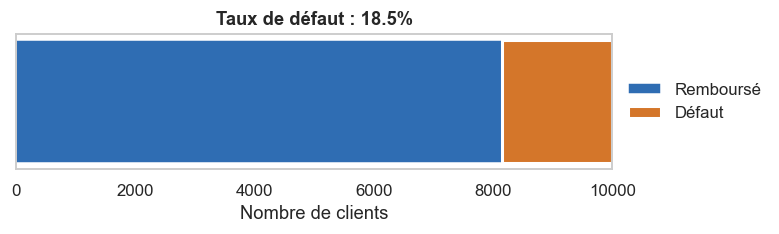

In [5]:
rate = data[TARGET].mean()
counts = data[TARGET].map(CLASS_NAMES).value_counts()

fig, ax = plt.subplots(figsize=(7, 1.6))
ax.barh([""], [counts["Remboursé"]], color=COLORS["Remboursé"], label="Remboursé")
ax.barh([""], [counts["Défaut"]], left=[counts["Remboursé"]], color=COLORS["Défaut"],
        label="Défaut", edgecolor="white", linewidth=2)
ax.set_xlim(0, len(data))
ax.set_xlabel("Nombre de clients")
ax.set_title(f"Taux de défaut : {rate:.1%}")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.grid(False)
plt.show()

18,5 % des clients sont en défaut, les classes sont donc déséquilibrées.
L'accuracy seule n'est pas suffisante, je regarde surtout la précision, le rappel et le F1.

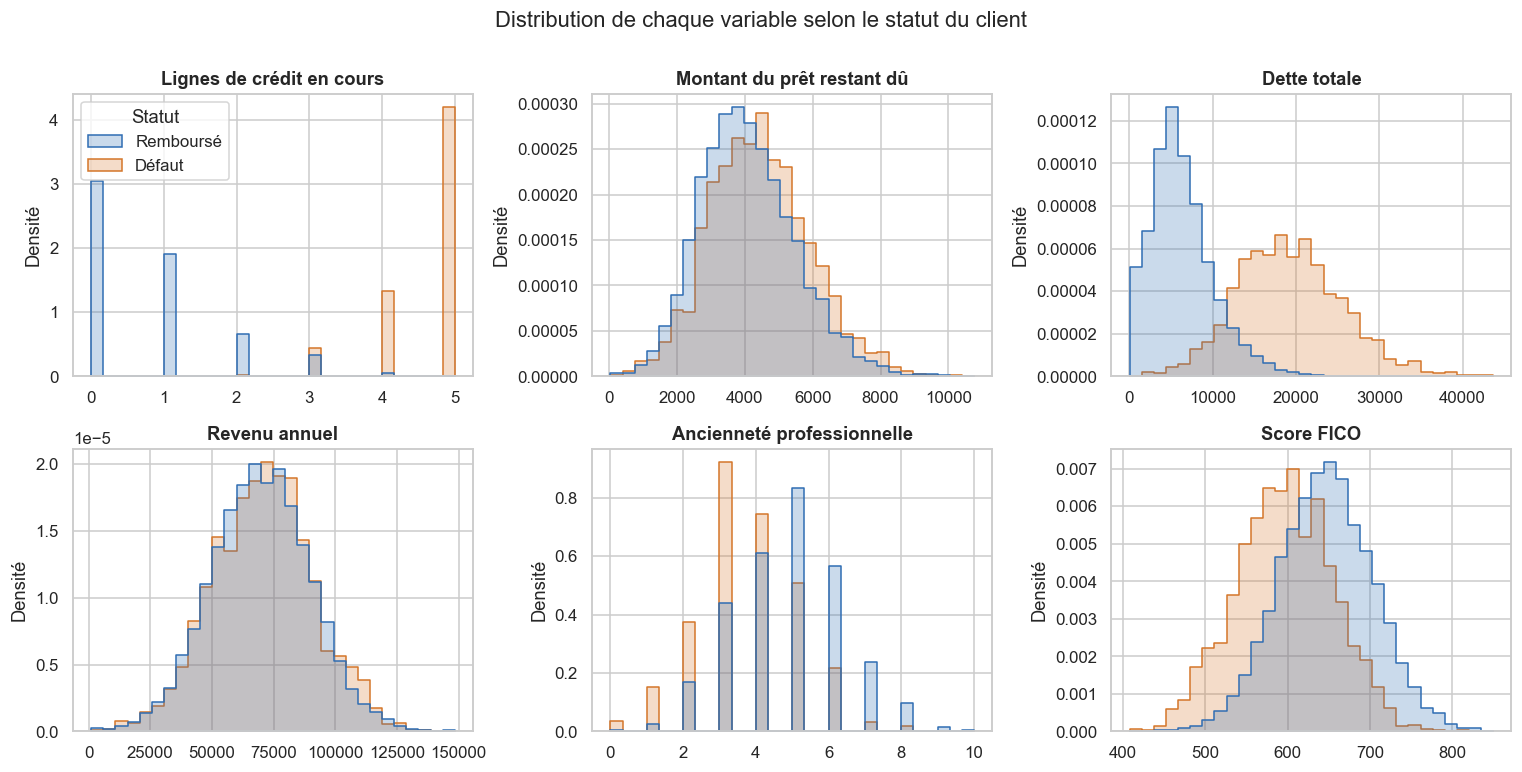

In [6]:
plot_data = data.assign(Statut=data[TARGET].map(CLASS_NAMES))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feature in zip(axes.flat, FEATURES):
    sns.histplot(plot_data, x=feature, hue="Statut", palette=COLORS, element="step",
                 stat="density", common_norm=False, bins=30, ax=ax, legend=ax is axes.flat[0])
    ax.set_title(LABELS[feature])
    ax.set_xlabel("")
    ax.set_ylabel("Densité")
fig.suptitle("Distribution de chaque variable selon le statut du client", y=1.0)
plt.tight_layout()
plt.show()

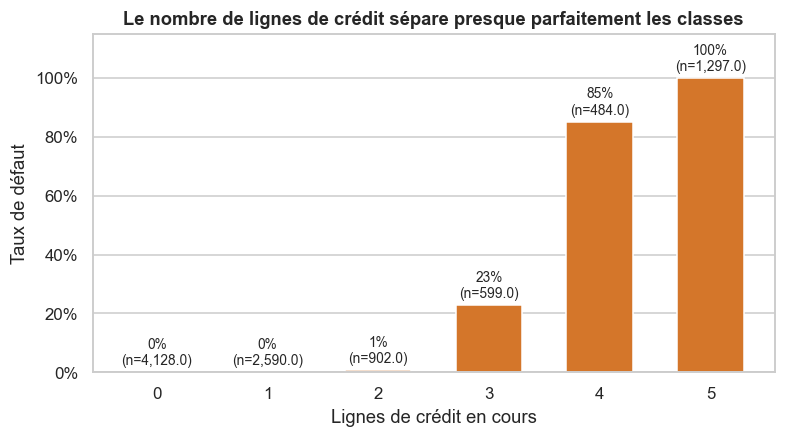

In [7]:
by_lines = data.groupby("credit_lines_outstanding")[TARGET].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_lines.index, by_lines["mean"], color=COLORS["Défaut"], width=0.6)
for x, (mean, size) in by_lines.iterrows():
    ax.annotate(f"{mean:.0%}\n(n={size:,})", (x, mean), ha="center", va="bottom",
                fontsize=9, xytext=(0, 3), textcoords="offset points")
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel(LABELS["credit_lines_outstanding"])
ax.set_ylabel("Taux de défaut")
ax.set_title("Le nombre de lignes de crédit sépare presque parfaitement les classes")
ax.grid(axis="x", visible=False)
plt.show()

Le nombre de lignes de crédit sépare presque parfaitement les deux classes.
Les données sont sans doute synthétiques, il faut donc s'attendre à des scores très élevés.

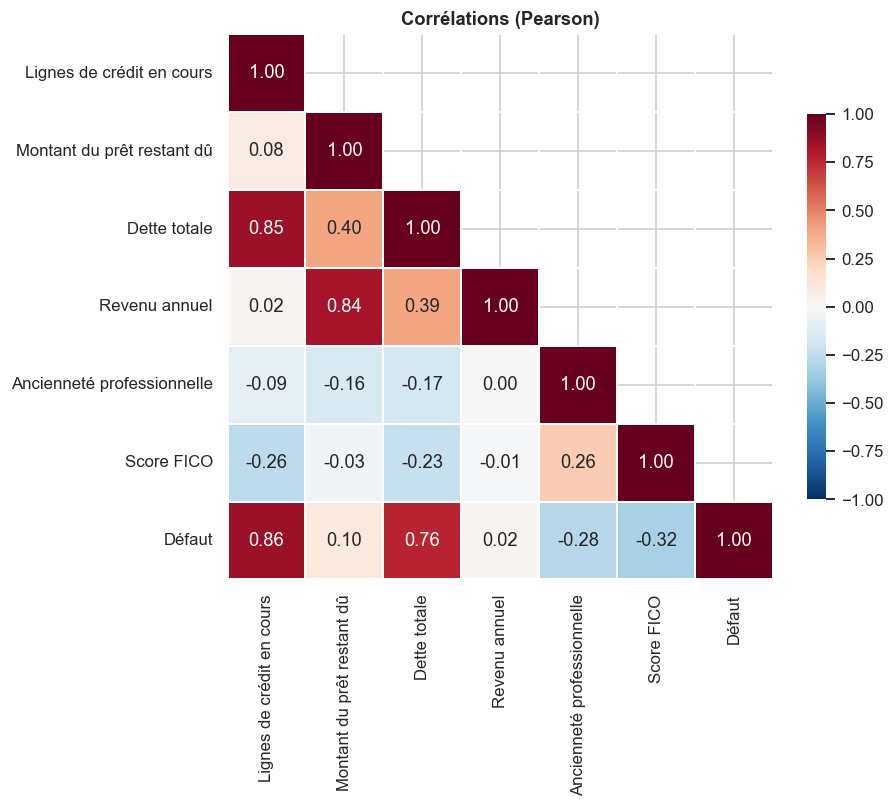

In [8]:
corr = data[FEATURES + [TARGET]].corr().rename(index=LABELS | {TARGET: "Défaut"},
                                               columns=LABELS | {TARGET: "Défaut"})
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Corrélations (Pearson)")
plt.show()

La dette totale est très corrélée au nombre de lignes de crédit (0,85).
Le score FICO et l'ancienneté sont liés négativement au défaut.

### Valeurs atypiques

Je garde les valeurs atypiques : elles restent plausibles (gros revenus, gros prêts).
Les traiter sur toute la base avant le découpage train/test créerait aussi une fuite de données.

In [9]:
numeric = FEATURES[1:]  # le nombre de lignes de crédit est un petit entier
q1, q3 = data[numeric].quantile(0.25), data[numeric].quantile(0.75)
iqr = q3 - q1
outliers = (data[numeric] < q1 - 1.5 * iqr) | (data[numeric] > q3 + 1.5 * iqr)
outliers.sum().rename(index=LABELS).to_frame("valeurs atypiques (IQR)")

,valeurs atypiques (IQR)
Montant du prêt restant dû,115
Dette totale,602
Revenu annuel,86
Ancienneté professionnelle,0
Score FICO,72


## 4. Découpage train / test

20 % des données sont gardées pour le test final. Les modèles sont comparés par validation croisée (5 plis)
sur le train. La standardisation est dans le pipeline, donc elle est apprise uniquement sur le train.

In [10]:
X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Entraînement : {len(X_train):,} clients, Test : {len(X_test):,} clients")
print(f"Taux de défaut - entraînement : {y_train.mean():.1%}, test : {y_test.mean():.1%}")

Entraînement : 8,000 clients, Test : 2,000 clients
Taux de défaut - entraînement : 18.5%, test : 18.5%


## 5. Comparaison des modèles

In [11]:
MODEL_NAMES = {
    "logistic_regression": "Régression logistique",
    "decision_tree": "Arbre de décision",
    "random_forest": "Forêt aléatoire",
    "gradient_boosting": "Gradient boosting",
}

rows = []
for name, pipeline in candidates().items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=CV_SCORING)
    for fold in range(cv.n_splits):
        rows.append({"modèle": MODEL_NAMES[name],
                     **{m: scores[f"test_{m}"][fold] for m in CV_SCORING}})
cv_scores = pd.DataFrame(rows)

summary = (cv_scores.groupby("modèle")[CV_SCORING].agg(["mean", "std"])
           .sort_values(("average_precision", "mean"), ascending=False))
summary

roc_auc       average_precision          f1      
                         mean   std              mean   std  mean   std
modèle                                                                 
Régression logistique   1.000 0.000             1.000 0.000 0.993 0.006
Gradient boosting       1.000 0.000             0.999 0.001 0.988 0.005
Forêt aléatoire         1.000 0.000             0.999 0.001 0.979 0.008
Arbre de décision       0.999 0.001             0.996 0.004 0.977 0.009

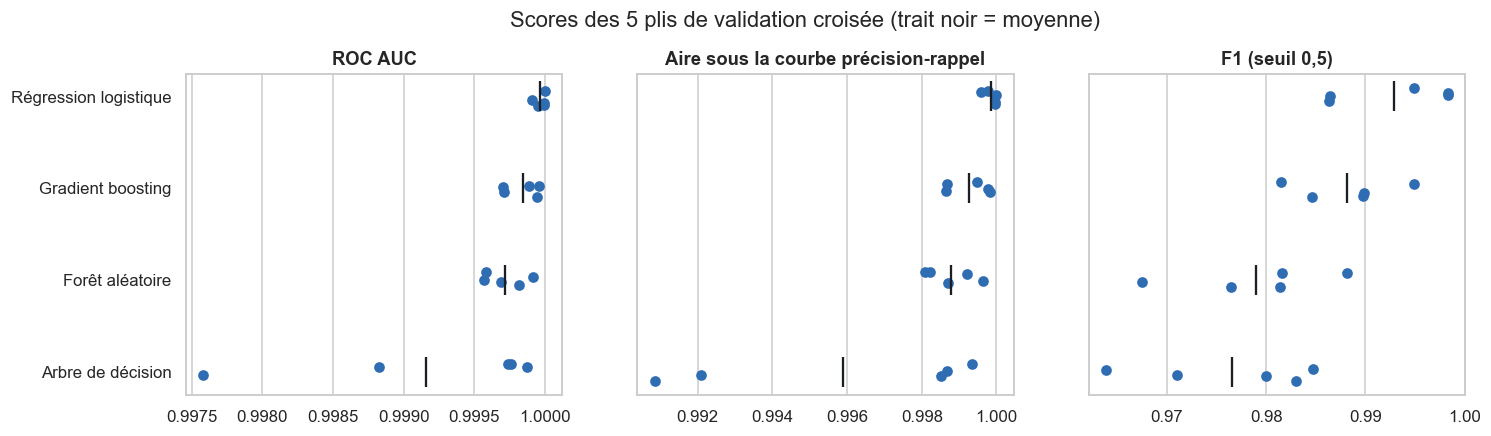

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
order = summary.index
titles = {"roc_auc": "ROC AUC", "average_precision": "Aire sous la courbe précision-rappel", "f1": "F1 (seuil 0,5)"}
for ax, metric in zip(axes, CV_SCORING):
    sns.stripplot(cv_scores, x=metric, y="modèle", order=order, color="#2f6db3", size=7, ax=ax)
    means = cv_scores.groupby("modèle")[metric].mean().reindex(order)
    ax.scatter(means, range(len(order)), marker="|", s=400, color="#1b1f23", zorder=3)
    ax.set_title(titles[metric])
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Scores des 5 plis de validation croisée (trait noir = moyenne)", y=1.03)
plt.show()

La régression logistique est la meilleure sur les trois métriques. Elle est aussi la plus simple
à expliquer, c'est donc le modèle que je retiens.

### Rééquilibrage des classes

Je compare trois options : aucun rééquilibrage, `class_weight='balanced'` et SMOTE (dans le pipeline).

In [13]:
def logistic(**kwargs):
    return LogisticRegression(max_iter=2000, random_state=SEED, **kwargs)

balancing = {
    "Aucun": Pipeline([("scaler", StandardScaler()), ("model", logistic())]),
    "class_weight='balanced'": Pipeline([("scaler", StandardScaler()),
                                         ("model", logistic(class_weight="balanced"))]),
    "SMOTE": ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=SEED)),
                          ("model", logistic())]),
}
pd.DataFrame({
    name: {m: cross_validate(p, X_train, y_train, cv=cv, scoring=CV_SCORING)[f"test_{m}"].mean()
           for m in CV_SCORING}
    for name, p in balancing.items()
}).T

,roc_auc,average_precision,f1
Aucun,1.000,1.000,0.993
class_weight='balanced',1.000,1.000,0.983
SMOTE,1.000,1.000,0.988


Le rééquilibrage n'apporte rien : l'AUC ne bouge pas et le F1 baisse.
Je garde donc le modèle sans rééquilibrage et j'ajuste plutôt le seuil.

## 6. Choix du seuil

Je prends le seuil qui maximise le F1, calculé en validation croisée (sans toucher au jeu de test).

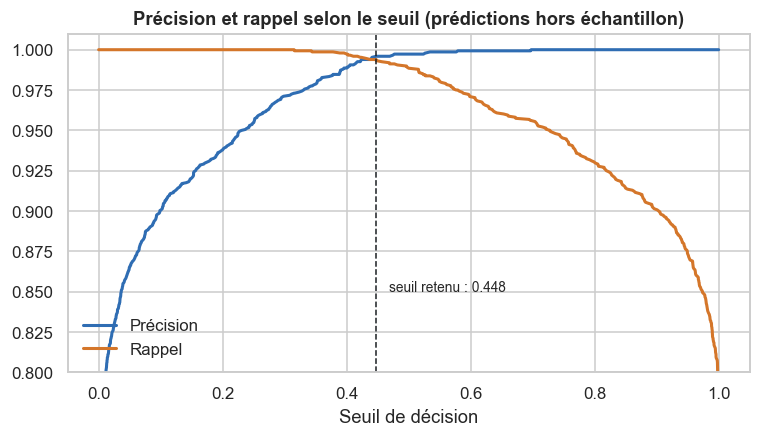

In [14]:
model = candidates()["logistic_regression"]
oof_prob = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
threshold = best_threshold(y_train, oof_prob)

precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, precision[:-1], color="#2f6db3", lw=2, label="Précision")
ax.plot(thresholds, recall[:-1], color="#d4762a", lw=2, label="Rappel")
ax.axvline(threshold, color="#1b1f23", ls="--", lw=1)
ax.annotate(f"seuil retenu : {threshold:.3f}", (threshold, 0.85), xytext=(8, 0),
            textcoords="offset points", fontsize=9)
ax.set_xlabel("Seuil de décision")
ax.set_ylim(0.8, 1.01)
ax.legend(frameon=False, loc="lower left")
ax.set_title("Précision et rappel selon le seuil (prédictions hors échantillon)")
plt.show()

## 7. Résultats sur le jeu de test

In [15]:
model.fit(X_train, y_train)
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

pd.Series(evaluate(y_test, y_prob, threshold), name="jeu de test").to_frame()

,jeu de test
accuracy,0.999
precision,0.995
recall,0.997
f1_score,0.996
roc_auc,1.000
average_precision,1.000
brier_score,0.003


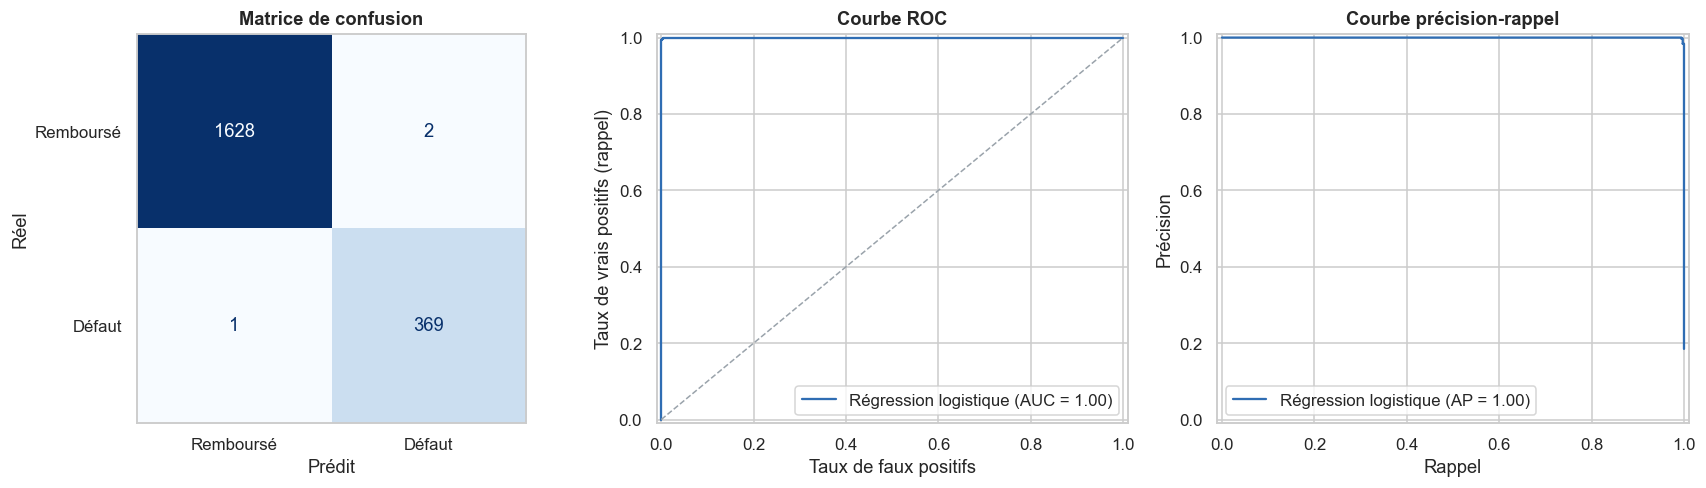

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=list(CLASS_NAMES.values()), cmap="Blues",
    colorbar=False, ax=axes[0])
axes[0].set(title="Matrice de confusion", xlabel="Prédit", ylabel="Réel")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], color="#2f6db3", name="Régression logistique")
axes[1].plot([0, 1], [0, 1], ls="--", color="#9aa3ab", lw=1)
axes[1].set(title="Courbe ROC", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs (rappel)")
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2], color="#2f6db3",
                                        name="Régression logistique")
axes[2].set(title="Courbe précision-rappel", xlabel="Rappel", ylabel="Précision")
for ax in axes[1:]:
    ax.set_aspect("auto")
plt.tight_layout()
plt.show()

Seulement 3 erreurs sur 2 000 clients. Les résultats sont proches de ceux de la validation croisée.

## 8. Interprétation

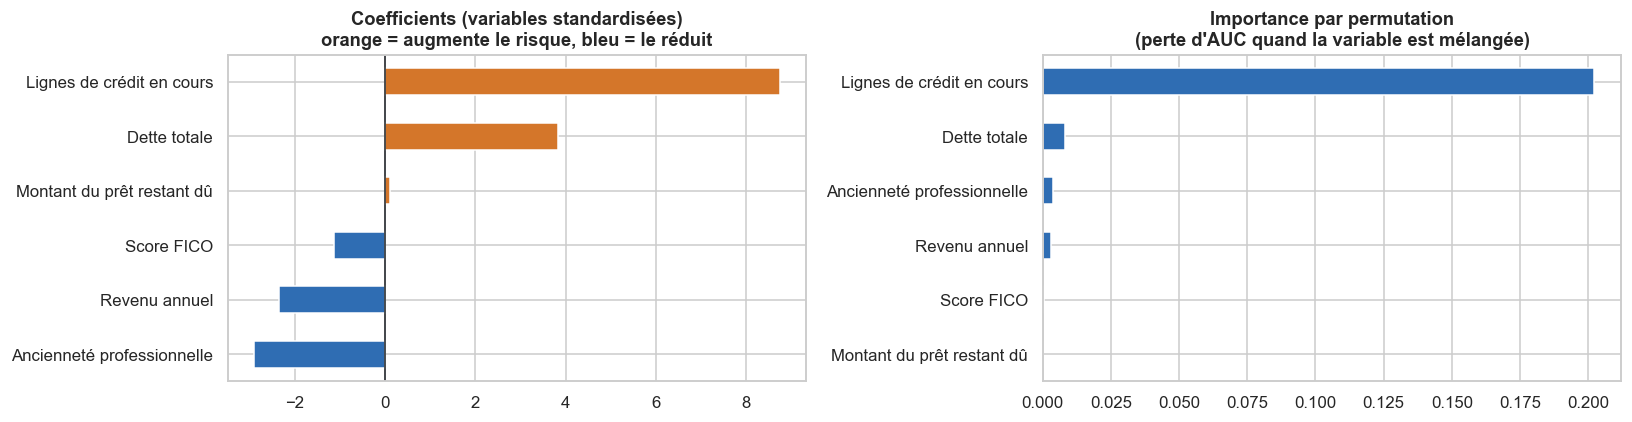

In [17]:
coefficients = pd.Series(model.named_steps["model"].coef_[0], index=FEATURES).rename(index=LABELS)
importance = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                                    n_repeats=10, random_state=SEED)
importance = pd.Series(importance.importances_mean, index=FEATURES).rename(index=LABELS)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
coefficients.sort_values().plot.barh(
    ax=axes[0], color=["#d4762a" if c > 0 else "#2f6db3" for c in coefficients.sort_values()])
axes[0].axvline(0, color="#1b1f23", lw=1)
axes[0].set_title("Coefficients (variables standardisées)\norange = augmente le risque, bleu = le réduit")
importance.sort_values().plot.barh(ax=axes[1], color="#2f6db3")
axes[1].set_title("Importance par permutation\n(perte d'AUC quand la variable est mélangée)")
plt.tight_layout()
plt.show()

Le nombre de lignes de crédit est de loin la variable la plus importante.
La dette totale augmente aussi le risque, alors que le revenu, l'ancienneté et le score FICO le réduisent.

### Erreurs du modèle

In [18]:
errors = X_test.assign(réel=y_test, probabilité=y_prob, prédit=y_pred).query("réel != prédit")
print(f"{len(errors)} erreurs sur {len(X_test):,} clients")
errors.rename(columns=LABELS).sort_values("probabilité")

3 erreurs sur 2,000 clients


,Lignes de crédit en cours,Montant du prêt restant dû,Dette totale,Revenu annuel,Ancienneté professionnelle,Score FICO,réel,probabilité,prédit
4825,3,"5,017.744","12,598.578","58,117.748",4,634,1,0.346,0
7379,3,"1,978.915","7,074.164","36,818.874",4,559,0,0.450,1
1915,4,"2,346.714","14,539.250","73,728.348",7,527,0,0.471,1


Les erreurs sont des cas proches du seuil, ce sont les dossiers à vérifier à la main.

## 9. Conclusion

Modèle retenu : régression logistique, avec un seuil de 0,448. Sur le test : AUC de 1,00 et F1 de 99,6 %.

Pour entraîner le modèle final : `python -m credit_risk.train`. Il est ensuite utilisé par l'API (FastAPI + Docker).

Limites : les données semblent synthétiques, les résultats seraient plus faibles sur des données réelles.
Il faudrait aussi tenir compte du coût d'une erreur dans le choix du seuil.